# 04 · Pest classification (MobileNetV3 → ONNX)

**Question the model answers:** *what is in this photo?* — nothing more. Cause, symptoms,
treatment, prevention and safety come from the reviewed knowledge base
(`backend/seeds/pests.json`), never from the model (spec §7).

| | |
|---|---|
| Dataset | [Agricultural Pests Image Dataset — Kaggle](https://www.kaggle.com/datasets/vencerlanz09/agricultural-pests-image-dataset) |
| Folder | save as `ml/data/archives/agricultural_pests.zip`, then run `python -m agrismart_ml.datasets` |
| Images / classes | ~5,500 / 12 (ants, bees, beetle, caterpillar, earthworms, earwig, grasshopper, moth, slug, snail, wasp, weevil) |
| Bigger option (v2) | [IP102](https://github.com/xpwu95/IP102) — 102 pest classes, 75k images |
| Model | MobileNetV3-Large, ImageNet weights, fine-tuned (EfficientNet-B0 also supported) |
| Serving | ONNX Runtime on CPU, optional INT8 quantisation |

No YOLO: we classify the whole photo; object detection is only needed to locate many pests in one image.

**Hardware.** A GPU makes this ~20× faster. On a laptop CPU use `PER_CLASS` below for a
quick run first; for the full run, a free Google Colab GPU works with the same code
(upload `ml/agrismart_ml` and the dataset).

In [1]:
import sys
from pathlib import Path

ML_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agrismart_ml.registry import ARTIFACTS_DIR, DATA_DIR

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 4)
print("Data folder:     ", DATA_DIR)
print("Artifacts folder:", ARTIFACTS_DIR)

Data folder:      C:\AgriSmart\ml\data\raw
Artifacts folder: C:\AgriSmart\ml\artifacts


In [2]:
from agrismart_ml import vision
from agrismart_ml.catalog import PEST_LABELS as LABELS

DATA = DATA_DIR / "pests"
assert DATA.exists(), f"Run: python -m agrismart_ml.datasets  (expected {DATA})"
import torch

ON_GPU = torch.cuda.is_available()
PER_CLASS = None   # 5.5k images train comfortably on CPU (about 30–60 minutes)
print("GPU" if ON_GPU else f"CPU ({torch.get_num_threads()} threads)")

CPU (10 threads)


One folder of classes: we make a stratified 70 / 15 / 15 train / validation / test split (seeded, reproducible).

In [3]:
class_root = vision.find_class_root(DATA, LABELS)
samples = vision.subsample(vision.scan(class_root, LABELS), PER_CLASS)
train_samples, valid_samples, test_samples = vision.stratified_split(samples, valid=0.15, test=0.15)
print(len(train_samples), "train /", len(valid_samples), "valid /", len(test_samples), "test")

3844 train / 825 valid / 825 test


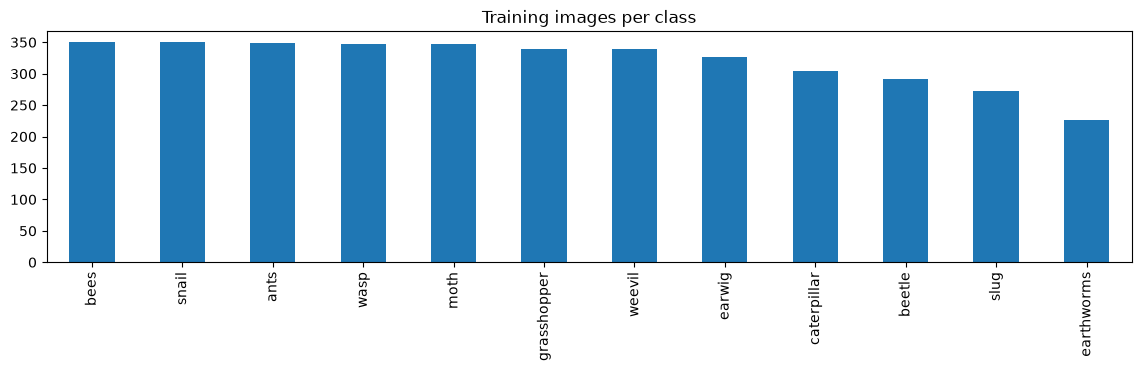

In [4]:
counts = pd.Series([label for _, label in train_samples]).value_counts()
counts.plot.bar(figsize=(14, 3), title="Training images per class");

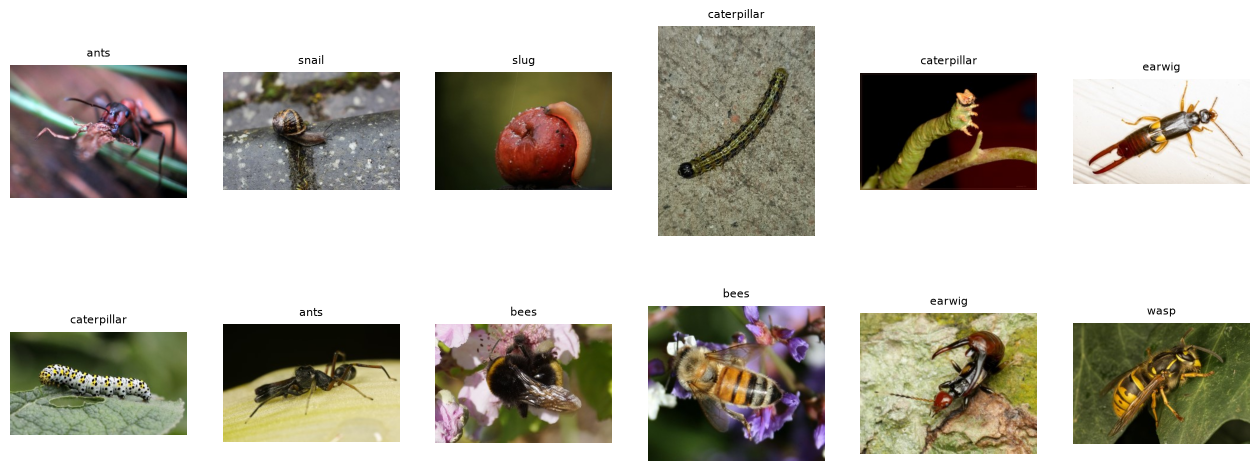

In [5]:
from PIL import Image

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, (path, label) in zip(axes.flat, pd.Series(train_samples).sample(12, random_state=1)):
    ax.imshow(Image.open(path)); ax.set_title(label, fontsize=8); ax.axis("off")

## Train
Stage 1 trains only the new classifier head; stage 2 fine-tunes the whole network at a lower learning rate. Early stopping keeps the best validation epoch.

In [6]:
config = vision.TrainConfig(
    architecture="mobilenet_v3_large",   # or "efficientnet_b0"
    image_size=224,
    batch_size=32,
    head_epochs=2,
    finetune_epochs=12,
    num_workers=4,                        # set 0 if the DataLoader hangs on Windows
)
trained = vision.train(train_samples, valid_samples, config)

Training mobilenet_v3_large on cpu — 3844 train / 825 valid images, 12 classes


[head] epoch 1/2  train 1.267/0.722  valid 0.963/0.850  (57s)


[head] epoch 2/2  train 0.994/0.837  valid 0.943/0.861  (42s)


[finetune] epoch 1/12  train 0.890/0.880  valid 0.847/0.893  (126s)


[finetune] epoch 2/12  train 0.759/0.931  valid 0.818/0.901  (228s)


...

[finetune] epoch 8/12  train 0.602/0.992  valid 0.735/0.937  (120s)


[finetune] epoch 9/12  train 0.589/0.995  valid 0.726/0.938  (123s)


[finetune] epoch 10/12  train 0.590/0.995  valid 0.723/0.939  (390s)


[finetune] epoch 11/12  train 0.584/0.995  valid 0.723/0.937  (128s)


[finetune] epoch 12/12  train 0.584/0.996  valid 0.724/0.941  (35709s)


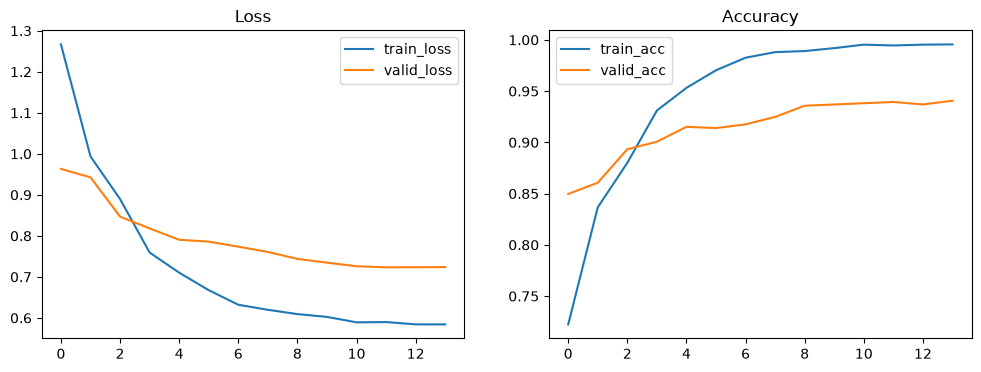

In [7]:
history = pd.DataFrame(trained.history)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
history[["train_loss", "valid_loss"]].plot(ax=a, title="Loss"); history[["train_acc", "valid_acc"]].plot(ax=b, title="Accuracy");

## Evaluate on the untouched test set
`min_confidence` is calibrated here: below it, accepted predictions would be less than 97 % accurate, so the app asks the farmer for a clearer photo instead of guessing.

In [8]:
metrics = vision.evaluate(trained, test_samples)
pd.Series({k: v for k, v in metrics.items() if k != "class_counts_test"})

test_accuracy                   0.9321
test_macro_f1                   0.9283
test_top3_accuracy              0.9782
min_confidence                  0.6000
coverage_at_min_confidence      0.8873
accuracy_at_min_confidence      0.9740
test_images                   825.0000
dtype: float64

In [9]:
from sklearn.metrics import classification_report

probabilities, targets = vision.predict_probabilities(trained.model, test_samples, trained.labels, config.image_size)
print(classification_report(targets, probabilities.argmax(1), target_names=trained.labels, digits=3))

              precision    recall  f1-score   support

        ants      0.937     0.987     0.961        75
        bees      0.960     0.960     0.960        75
      beetle      0.833     0.806     0.820        62
 caterpillar      0.838     0.877     0.857        65
  earthworms      0.955     0.875     0.913        48
      earwig      0.899     0.886     0.892        70
 grasshopper      0.957     0.918     0.937        73
        moth      0.938     1.000     0.968        75
        slug      0.945     0.881     0.912        59
       snail      0.974     1.000     0.987        75
        wasp      0.973     0.960     0.966        75
      weevil      0.959     0.973     0.966        73

    accuracy                          0.932       825
   macro avg      0.931     0.927     0.928       825
weighted avg      0.932     0.932     0.932       825



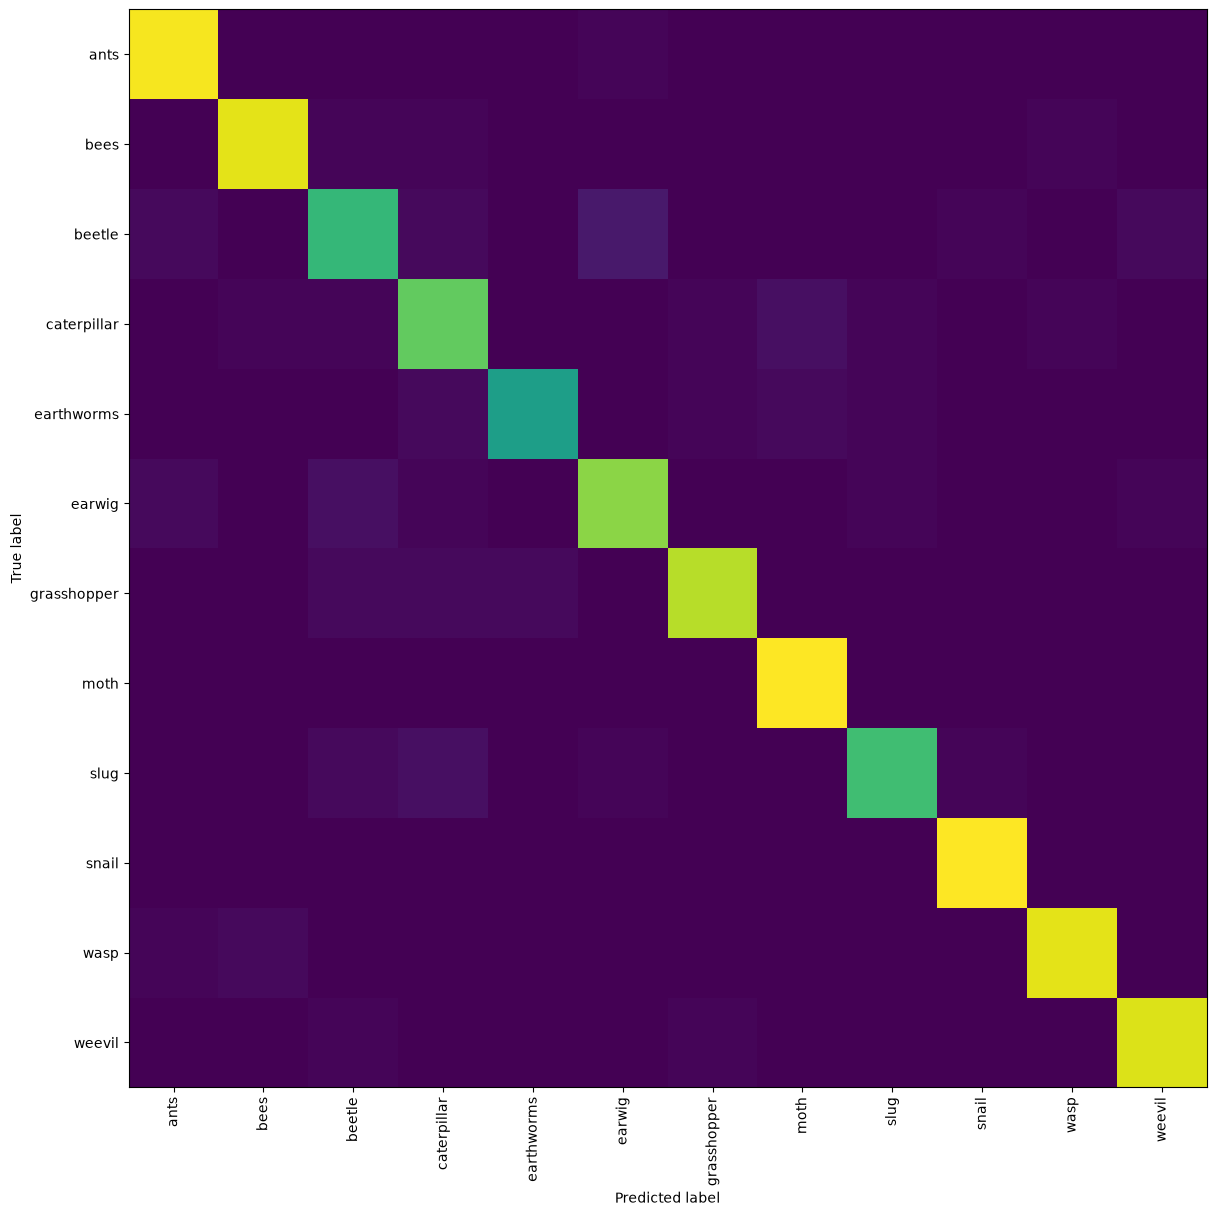

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(targets, probabilities.argmax(1), display_labels=trained.labels,
                                        xticks_rotation=90, ax=ax, colorbar=False, include_values=False)

## Export to ONNX (+ INT8 if it keeps accuracy)
The export is checked numerically against PyTorch. INT8 is calibrated on validation images and served only if it loses ≤ 1 accuracy point.

In [11]:
directory = vision.export_onnx(trained, "pest", DATA, quantize_with=valid_samples)

[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...


[torch.onnx] Optimize the ONNX graph... ✅


ONNX matches PyTorch (max abs diff 3.22e-06)


Quantisation: {'fp32_accuracy': 0.915, 'int8_accuracy': 0.705, 'served': 'fp32', 'fp32_mb': 17.2, 'int8_mb': 4.9}


Exported C:\AgriSmart\ml\artifacts\pest\pest_v1


## Put the model live

Versions are never overwritten — each export creates a new `…_vN` folder. To serve it:

* **Admin dashboard → Models →** *Register* and tick *Activate*, or
* from `backend/`: `python -m app.cli register-model pest <version> --activate`

Rolling back is the same command with the previous version (`activate-model`). Every API
instance picks up the change within a minute — no restart.